# Task 4.1 - CNN
Goal: Build a CNN to predict which class the image from the dataset belongs to, figuring out what each dinosaur should be fed.    
Deadline: 1st February

In [134]:
import numpy as np
import random
import seaborn as sns
import matplotlib.pyplot as plt

import os
import cv2

import torch
import torch.nn as nn
import torch.nn.functional as F

from torch.utils.data import TensorDataset, DataLoader, random_split
from sklearn.metrics import confusion_matrix

In [135]:
def load_images_from_folder(base_path, class_to_label, img_size=(64, 64)):
    X = []
    Y = []

    for class_name, label in class_to_label.items():
        class_folder = os.path.join(base_path, class_name)

        for file in os.listdir(class_folder):
            img_path = os.path.join(class_folder, file)

            # Read image in grayscale
            img = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)

            if img is None:
                continue  # skip corrupted files

            # Resize
            img = cv2.resize(img, img_size)

            X.append(img)
            Y.append(label)

    return np.array(X), np.array(Y)

In [136]:
class_to_label = {
    "Apatosaur Aphie's Apples": 0,
    "Bluplocephalus Bob's Blueberries": 1,
    "Cherizinoasaur Cher's Cherries": 2,
    "Corythosaurus Cory's Corn": 3,
    "Grapthorina Greta's Grapes": 4,
    "Pachycephalosaurus Perry's Peaches": 5,
    "Pepteranodon Pep's Peppers": 6,
    "Potoceratops Pott's Potatoes": 7,
    "Rhaspdodon Ribery's Raspberries": 8,
    "Stribecosaurus Stan's Strawberries": 9,
    "Thyreosaur Tim's Thyme": 10
}

X_train, Y_train = load_images_from_folder("data/veggie_heap_training/", class_to_label)
X_test, Y_test = load_images_from_folder("data/veggie_heap_testing", class_to_label)

In [137]:
#Adding a new channel dimension
X_train = X_train[..., np.newaxis]
X_test = X_test[..., np.newaxis]
#Checking shape 
print("Train X shape:", X_train.shape)
print("Train Y shape:", Y_train.shape)
print("Test X shape:", X_test.shape)
print("Test Y shape:", Y_test.shape)
print("Unique labels:", np.unique(Y_train))

Train X shape: (8905, 64, 64, 1)
Train Y shape: (8905,)
Test X shape: (2211, 64, 64, 1)
Test Y shape: (2211,)
Unique labels: [ 0  1  2  3  4  5  6  7  8  9 10]


In [138]:
#Normalizing pixel values to prevent exploding gradients
X_train = X_train / 255.0
X_test = X_test / 255.0

In [139]:
# Convert to Pytorch Format

X_train_torch = torch.tensor(X_train, dtype=torch.float32).permute(0, 3, 1, 2)
X_test_torch = torch.tensor(X_test, dtype=torch.float32).permute(0, 3, 1, 2)

Y_train_torch = torch.tensor(Y_train, dtype=torch.long)
Y_test_torch = torch.tensor(Y_test, dtype=torch.long)

print("Train X shape:", X_train_torch.shape)
print("Train Y shape:", Y_train_torch.shape)
print("Test X shape:", X_test_torch.shape)
print("Test Y shape:", Y_test_torch.shape)

Train X shape: torch.Size([8905, 1, 64, 64])
Train Y shape: torch.Size([8905])
Test X shape: torch.Size([2211, 1, 64, 64])
Test Y shape: torch.Size([2211])


### Personal Notes
* (N,C,H,W)->expected shape for input in pytorch (C=channel)
* No need for one hot encoding since pytorch expects integer labels since we are using nn.CrossEntopyLoss() which already:
    1. Applies Softmax
    2. Computes Cross-Entropy Loss 
* So, model output will also be raw logits[NO Softmax], since nn.CrossEntopyLoss() handles that 
* Dataloader(Pytorch Concept): Used for processing data samples. Handles:
    1. Batching (Dividing samples into batches) 
    2. Shuffling (Prevents learning order-based patters) 
    3. Results in efficient memory usage + Doesn't overload RAM/GPU + cleaner training loop

In [140]:
# Create DataLoader

train_dataset = TensorDataset(X_train_torch, Y_train_torch)
test_dataset = TensorDataset(X_test_torch, Y_test_torch)

train_size = int(0.8 * len(train_dataset))
val_size = len(train_dataset) - train_size

train_dataset, val_dataset = random_split(train_dataset, [train_size, val_size])

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True)
val_loader = DataLoader(val_dataset, batch_size=32)
test_loader = DataLoader(test_dataset, batch_size=32)

In [ ]:
# Define CNN model

class CNN(nn.Module):
    def __init__(self):
        super(CNN, self).__init__()

        self.conv1 = nn.Conv2d(1, 32, 3)    # feature extraction
        self.conv2 = nn.Conv2d(32, 64, 3)   # deeper features
        self.conv3 = nn.Conv2d(64, 128, 3)  # complex patterns

        self.pool = nn.MaxPool2d(2,2)

        self.fc1 = nn.Linear(128 * 6 * 6, 64)  # reasoning layer
        self.fc2 = nn.Linear(64, 11)           # classification

        #self.dropout = nn.Dropout(0.5)

    def forward(self, X):
        X = self.pool(F.relu(self.conv1(X)))    # (32, 31, 31)
        X = self.pool(F.relu(self.conv2(X)))    # (64, 14, 14)
        X = self.pool(F.relu(self.conv3(X)))    # (128, 6, 6)

        X = X.view(X.size(0), -1)

        X = F.relu(self.fc1(X))
        #X = self.dropout(X)
        X = self.fc2(X)

        return X

In [142]:
# Training setup

model = CNN()

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)

In [143]:
epochs = 10
train_accs = []
val_accs = []

for epoch in range(epochs):

    # TRAINING
    model.train()
    correct = 0
    total = 0
    running_loss = 0

    for images, labels in train_loader:
        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        _, predicted = torch.max(outputs, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    train_acc = correct / total

    # VALIDATION 
    model.eval()
    val_correct = 0
    val_total = 0

    with torch.no_grad():
        for images, labels in val_loader:
            outputs = model(images)
            _, predicted = torch.max(outputs, 1)

            val_total += labels.size(0)
            val_correct += (predicted == labels).sum().item()

    val_acc = val_correct / val_total

    train_accs.append(train_acc)
    val_accs.append(val_acc)

    print(f"Epoch {epoch+1}, Train Acc: {train_acc:.4f}, Val Acc: {val_acc:.4f}")

Epoch 1, Train Acc: 0.3812, Val Acc: 0.6451
Epoch 2, Train Acc: 0.6276, Val Acc: 0.7524
Epoch 3, Train Acc: 0.6954, Val Acc: 0.7743
Epoch 4, Train Acc: 0.7423, Val Acc: 0.8310
Epoch 5, Train Acc: 0.7761, Val Acc: 0.8490
Epoch 6, Train Acc: 0.7958, Val Acc: 0.8832
Epoch 7, Train Acc: 0.8231, Val Acc: 0.8798
Epoch 8, Train Acc: 0.8391, Val Acc: 0.8899
Epoch 9, Train Acc: 0.8435, Val Acc: 0.9029
Epoch 10, Train Acc: 0.8498, Val Acc: 0.9057


In [144]:
# Evaluation
all_preds = []
all_labels = []

model.eval()
correct = 0
total = 0

with torch.no_grad():
    for images, labels in test_loader:
        outputs = model(images)
        _, predicted = torch.max(outputs, 1)

        total += labels.size(0)
        correct += (predicted == labels).sum().item()

        all_preds.extend(predicted.numpy())
        all_labels.extend(labels.numpy())

print("Test Accuracy:", correct / total)

Test Accuracy: 0.5762098597919494


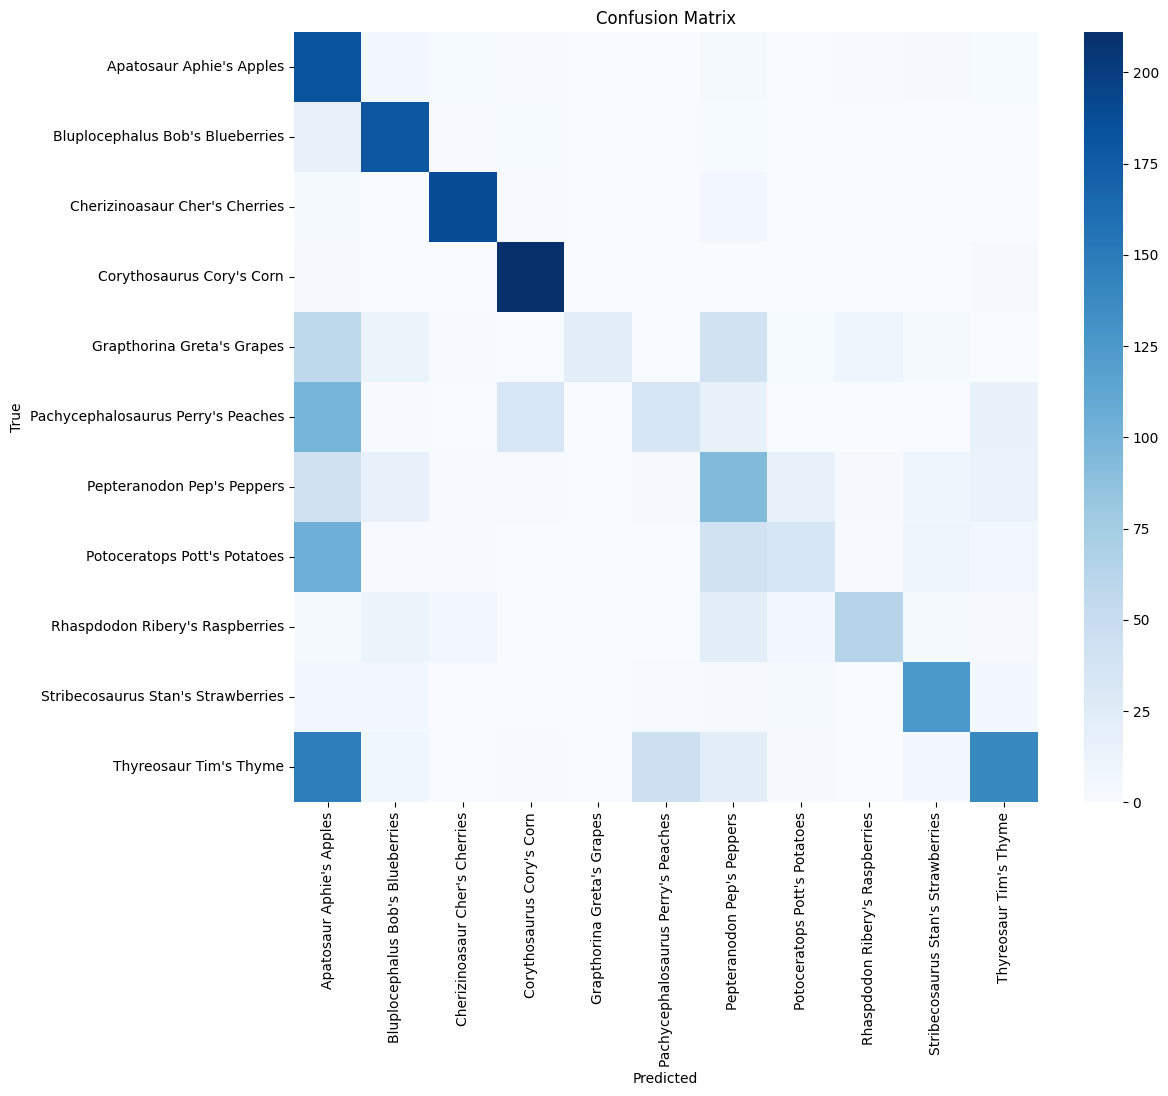

In [145]:
class_names = list(class_to_label.keys())
cm = confusion_matrix(all_labels, all_preds)
plt.figure(figsize=(12,10))
sns.heatmap(cm, annot=False, cmap='Blues',
            xticklabels=class_names,
            yticklabels=class_names)

plt.xticks(rotation=90)
plt.yticks(rotation=0)
plt.xlabel("Predicted")
plt.ylabel("True")
plt.title("Confusion Matrix")
plt.show()

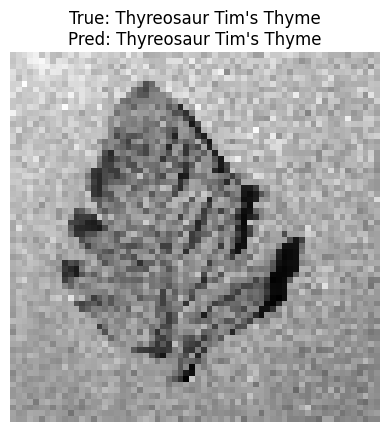

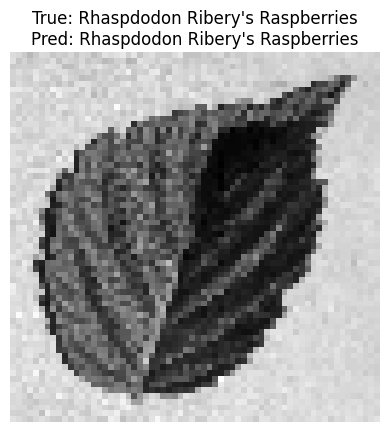

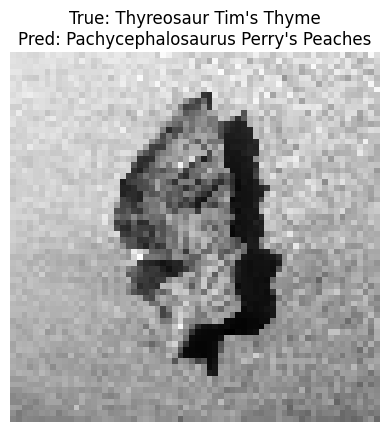

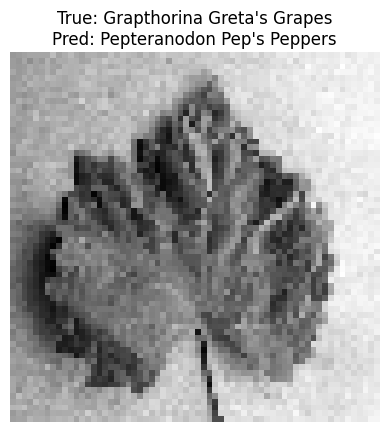

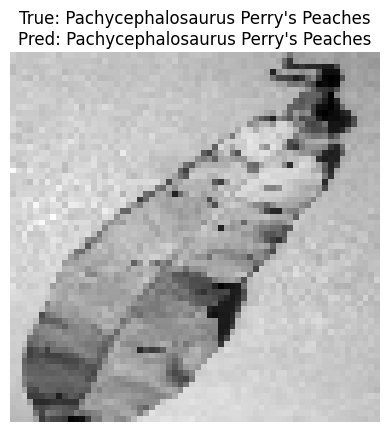

In [146]:
# Prediction Visualization

for _ in range(5):
    idx = random.randint(0, len(X_test_torch)-1)
    
    image = X_test_torch[idx]
    label = Y_test[idx]

    with torch.no_grad():
        output = model(image.unsqueeze(0))
        _, pred = torch.max(output, 1)

    plt.imshow(image.squeeze(), cmap='gray')
    plt.title(f"True: {class_names[label]}\nPred: {class_names[pred.item()]}")
    plt.axis('off')
    plt.show()

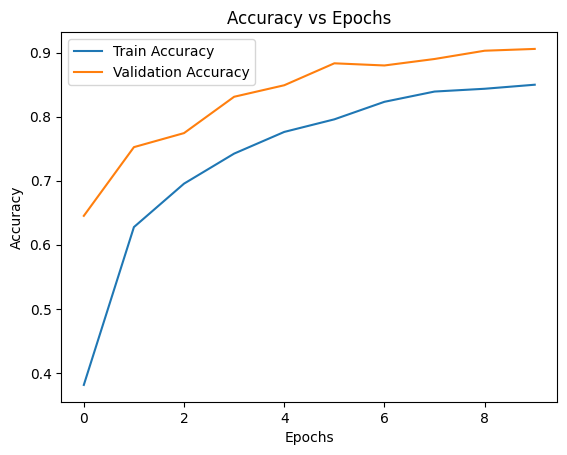

In [147]:
# Training Graphs

plt.plot(train_accs, label="Train Accuracy")
plt.plot(val_accs, label="Validation Accuracy")

plt.xlabel("Epochs")
plt.ylabel("Accuracy")
plt.legend()
plt.title("Accuracy vs Epochs")
plt.show()

## Final Results and Conclusion

* 
* 
* 